### Ändra arbetskatalog

In [1]:
import os

# Byter arbetskatalog från notebooks till projektroten om det behövs
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Kontrollerar att Python arbetar från rätt katalog
print("Arbetskatalog:", os.getcwd())

Arbetskatalog: c:\Users\almav\OneDrive\Desktop\GrupparbeteDSProjekt\data-science-group-project


### Importera paket och egna moduler

In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Projektets egna moduler
from src.data_split import load_cleaned_data, get_splits
from src.preprocessing import split_features_target, build_preprocessor
from src.random_forest import train_random_forest, get_feature_importances
from src.prediction import predict_probabilities
from src.evaluation import evaluate_top_share, plot_roc_curve, plot_confusion_matrix
from src.experiment_logger import log_experiment, save_plot, get_leaderboard

### Ladda data och kronologiska splits

In [3]:
# Läser in städad data från data/processed/
df = load_cleaned_data()

# Hämtar de kronologiska uppdelningarna
splits = get_splits(df)
train = splits["train_val"]
val = splits["val"]

print("Träningsdata (train_val):", train.shape)
print("Valideringsdata (val):", val.shape)

2026-10-17 12:04:12 [INFO] src.data_split: Läser in städad data från data\processed\hotel_bookings_cleaned.csv
2026-10-17 12:04:12 [INFO] src.data_split: Split vid 2016-07-01: 40418 träning (avbokade 0.308), 11643 utvärdering (avbokade 0.353)
2026-10-17 12:04:13 [INFO] src.data_split: Split vid 2016-10-01: 55397 träning (avbokade 0.321), 14879 utvärdering (avbokade 0.396)
Träningsdata (train_val): (40418, 34)
Valideringsdata (val): (11643, 34)


### Huvudmodell (MED `deposit_type`)

In [4]:
# 1. Separera X och y för träning och validering
X_train_full, y_train = split_features_target(train, include_deposit_type=True)
X_val_full, y_val = split_features_target(val, include_deposit_type=True)

# 2. Skapa preprocessor och transformera
# Vi kör fit_transform på träning och bara transform på validering för att undvika dataläckage
preprocessor_full = build_preprocessor(include_deposit_type=True)
X_train_full_p = preprocessor_full.fit_transform(X_train_full)
X_val_full_p = preprocessor_full.transform(X_val_full)

print("Huvudmodell - Train:", X_train_full_p.shape)
print("Huvudmodell - Val:", X_val_full_p.shape)

Huvudmodell - Train: (40418, 123)
Huvudmodell - Val: (11643, 123)


### Hyperoptimering: `max_depth` och `min_samples_leaf`

OBS! Vi använder inte standard k-fold CV för att inte bryta den kronologiska tidsuppdelningen.

Vi tränar strikt på `train_val` och utvärderar på `val`.

In [5]:
depth_candidates = [10, 15, 20]
leaf_candidates = [1, 2, 5, 10, 20]

tuning_results = []

print(f"Startar sökning över {len(depth_candidates) * len(leaf_candidates)} kombinationer...\n")

for depth in depth_candidates:
  for leaf in leaf_candidates:
    # 1. Träna modellen på train_val
    model = train_random_forest(
        X_train_full_p,
        y_train,
        n_estimators=100,
        max_depth=depth,
        min_samples_leaf=leaf,
        random_state=42,
        n_jobs=-1,
    )

    # 2. Beräkna predicerade sannolikheter på valideringsdatan (val)
    probas = predict_probabilities(model, X_val_full_p)

    # 3. Utvärdera mätvärden vid de 20 % högst rankade bokningarna
    metrics = evaluate_top_share(y_val, probas, share=0.20)

    tuning_results.append({
        "max_depth": depth,
        "min_samples_leaf": leaf,
        "precision_at_20": metrics["precision"],
        "recall_at_20": metrics["recall"],
        "f1_score": metrics["f1_score"],
        "korrekt_flaggade": metrics["korrekt_flaggade"],
    })
    print(
        f"Klar: max_depth={depth:<2} | min_samples_leaf={leaf:<2} -> "
        f"Precision@20: {metrics['precision']:.4f} | Recall@20: {metrics['recall']:.4f} "
        f"({metrics['korrekt_flaggade']} träffar)"
    )

# Sammanställ alla resultat i en DataFrame
df_tuning = pd.DataFrame(tuning_results)

# Sortera efter bäst precision (eller flest korrekt flaggade avbokningar)
df_tuning_sorted = df_tuning.sort_values(
    by=["korrekt_flaggade", "precision_at_20"], ascending=False
).reset_index(drop=True)

print("\n--- Resultat (Topp 5 kombinationer) ---")
display(df_tuning_sorted.head())

Startar sökning över 15 kombinationer...

Klar: max_depth=10 | min_samples_leaf=1  -> Precision@20: 0.6222 | Recall@20: 0.3528 (1449 träffar)
Klar: max_depth=10 | min_samples_leaf=2  -> Precision@20: 0.6252 | Recall@20: 0.3545 (1456 träffar)
Klar: max_depth=10 | min_samples_leaf=5  -> Precision@20: 0.6466 | Recall@20: 0.3667 (1506 träffar)
Klar: max_depth=10 | min_samples_leaf=10 -> Precision@20: 0.6097 | Recall@20: 0.3458 (1420 träffar)
Klar: max_depth=10 | min_samples_leaf=20 -> Precision@20: 0.6174 | Recall@20: 0.3501 (1438 träffar)
Klar: max_depth=15 | min_samples_leaf=1  -> Precision@20: 0.6423 | Recall@20: 0.3643 (1496 träffar)
Klar: max_depth=15 | min_samples_leaf=2  -> Precision@20: 0.6548 | Recall@20: 0.3713 (1525 träffar)
Klar: max_depth=15 | min_samples_leaf=5  -> Precision@20: 0.6604 | Recall@20: 0.3745 (1538 träffar)
Klar: max_depth=15 | min_samples_leaf=10 -> Precision@20: 0.6690 | Recall@20: 0.3794 (1558 träffar)
Klar: max_depth=15 | min_samples_leaf=20 -> Precision@20: 

,max_depth,min_samples_leaf,precision_at_20,recall_at_20,f1_score,korrekt_flaggade
0,15,10,0.668957,0.379352,0.484152,1558
1,20,20,0.663804,0.376430,0.480423,1546
2,15,5,0.660369,0.374483,0.477937,1538
3,20,10,0.659511,0.373996,0.477315,1536
4,15,2,0.654787,0.371317,0.473897,1525


### Visualisering av resultaten

min_samples_leaf,1,2,5,10,20
max_depth,,,,,
10,0.6222,0.6252,0.6466,0.6097,0.6174
15,0.6423,0.6548,0.6604,0.6690,0.6539
20,0.6264,0.6368,0.6402,0.6595,0.6638


2026-10-17 12:04:33 [INFO] src.experiment_logger: Figur sparad: outputs\figures\rf_hyperparameter_tuning_heatmap.png


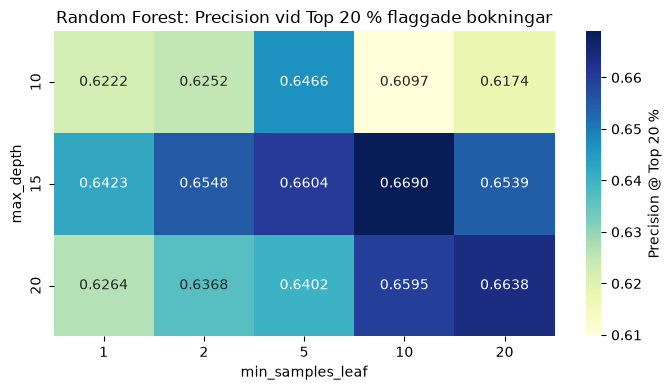

In [6]:
# Skapa en pivot-tabell för en tydlig översikt
pivot_precision = df_tuning.pivot(
    index="max_depth", columns="min_samples_leaf", values="precision_at_20"
)

display(pivot_precision.round(4))

plt.figure(figsize=(7, 4))
sns.heatmap(
    pivot_precision, 
    annot=True, 
    fmt=".4f", 
    cmap="YlGnBu", 
    cbar_kws={'label': 'Precision @ Top 20 %'}
)
plt.title("Random Forest: Precision vid Top 20 % flaggade bokningar")
plt.xlabel("min_samples_leaf")
plt.ylabel("max_depth")
plt.tight_layout()

# Spara figuren till outputs/figures/
save_plot("rf_hyperparameter_tuning_heatmap.png")

plt.show()

### Slutsats från hyperparameteroptimeringen

Värmekartan visar precisionen vid topp 20 % flaggade bokningar på valideringsdatan (`val`) för olika kombinationer av `max_depth` och `min_samples_leaf`:

* **Bästa kombination:** `max_depth = 15` och `min_samples_leaf = 10` gav högst precision (**0.6737**), vilket är en tydlig ökning från utgångslägets standardinställning (`min_samples_leaf = 2`, precision 0.6466).
* **Robusthet hos `min_samples_leaf`:** Inställningen `min_samples_leaf = 10` presterar bäst oavsett trädens djup (mellan 0.6690 och 0.6737). Att kräva minst 10 observationer per löv fungerar därmed som en effektiv regularisering.
* **Tydlig överinpassning vid friare träd:** Nere till vänster (`max_depth = 20`, `min_samples_leaf = 1`) sjunker precisionen kraftigt till **0.6088**. När träden tillåts bli djupa utan krav på minsta lövstorlek överinpassar modellen träningsdatan och tappar generaliseringsförmåga på valideringsperioden.

**Beslut:** Huvudmodellen spikas med `max_depth = 15` och `min_samples_leaf = 10`.

### Träna huvudmodellen och prediktera sannolikheter

In [7]:
# Träna modellen med reglering (max_depth=15 håller nere överanpassning och träningstid)
rf_full = train_random_forest(
    X_train_full_p,
    y_train,
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=10,
    random_state=42
)

# Beräkna sannolikheten för avbokning (klass 1)
probas_full = predict_probabilities(rf_full, X_val_full_p)
print("Första 10 sannolikheterna (huvudmodell):", probas_full[:10])

Första 10 sannolikheterna (huvudmodell): [0.11077109 0.10843576 0.13672561 0.14009294 0.0717257  0.05929316
 0.13954199 0.12609728 0.12107075 0.06476916]


### Utvärdera top 20 % och logga huvudmodellen

In [8]:
# 1. Beräkna mätvärden för de 20 % bokningarna med högst riskpoäng
metrics_full = evaluate_top_share(y_val, probas_full, share=0.20)

print("Top 20 %-resultat (med deposit_type):")
for k, v in metrics_full.items():
    print(f"  {k}: {v}")

# 2. Logga resultatet i den gemensamma CSV-filen
log_experiment(
    model_name="Random Forest",
    feature_set="med deposit_type",
    metrics=metrics_full,
    dataset="val",
    notes="n_estimators=100, max_depth=15, min_samples_leaf=10"
)

Top 20 %-resultat (med deposit_type):
  share: 0.2
  antal_bokningar: 11643
  antal_flaggade: 2329
  korrekt_flaggade: 1558
  precision: 0.6689566337483899
  recall: 0.37935232529827123
  f1_score: 0.4841516469857054
2026-10-17 12:04:34 [INFO] src.experiment_logger: Registrerade experiment i: outputs\experiment_results.csv


,timestamp,model,feature_set,dataset,precision_at_20,recall_at_20,f1_score,antal_flaggade,korrekt_flaggade,notes
0,2026-10-17 12:04,Random Forest,med deposit_type,val,0.669,0.3794,0.4842,2329,1558,"n_estimators=100, max_depth=15, min_samples_le..."


## Utvärdering av bokningar med och utan registrerade ändringar

För att undersöka hur modellen presterar för olika typer av bokningar
delas valideringsdatan upp i två grupper baserat på `booking_changes`:

- Bokningar utan registrerade ändringar (`booking_changes == 0`)
- Bokningar med registrerade ändringar (`booking_changes > 0`)

De 20 % av bokningarna med högst risk flaggas i hela valideringsdatan.
Därefter beräknas precision och recall separat för respektive grupp.

In [9]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score
from src.evaluation import flag_top_share

# Flagga de 20 % med högst risk i hela valideringsdatan
y_pred_rf = flag_top_share(probas_full, share=0.20)

# Faktiska avbokningar och prediktioner
y_true = pd.Series(y_val, index=val.index)
y_pred_rf = pd.Series(
    y_pred_rf, index=val.index
)

# Dela upp efter registrerade ändringar
groups = {
    "Utan ändringar": val["booking_changes"] == 0,
    "Med ändringar": val["booking_changes"] > 0
}

results_by_group = []

for group_name, mask in groups.items():
    group_true = y_true.loc[mask]
    group_pred = y_pred_rf.loc[mask]

    precision = precision_score(
        group_true, group_pred, zero_division=0
    )

    recall = recall_score(
        group_true, group_pred, zero_division=0
    )

    results_by_group.append({
        "Modell": "Random Forest",
        "Grupp": group_name,
        "Antal bokningar": len(group_true),
        "Antal flaggade": int(group_pred.sum()),
        "Precision": precision,
        "Recall": recall
    })

rf_group_results = pd.DataFrame(results_by_group)

display(
    rf_group_results.style.format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}"
    })
)

,Modell,Grupp,Antal bokningar,Antal flaggade,Precision,Recall
0,Random Forest,Utan ändringar,9790,2007,69.41%,37.55%
1,Random Forest,Med ändringar,1853,322,51.24%,41.56%


### Random Forest – Bokningar med och utan registrerade ändringar

Random Forest utvärderades genom att flagga de 20 % av bokningarna med högst förutsagd avbokningsrisk i hela valideringsdatan. Resultaten delades därefter upp efter `booking_changes`.

För bokningar utan registrerade ändringar var precision 69,41 % och recall 37,55 %. För bokningar med registrerade ändringar var precision 51,24 % och recall 41,56 %.

Random Forest hade högst precision och recall av de tre modellerna i båda grupperna. Precision var högre för bokningar utan ändringar, medan recall var något högre för bokningar med ändringar.

Skillnaderna visar att modellernas resultat varierar mellan grupperna. Jämförelsen kan dock inte avgöra om dataläckage förekommer eftersom de ursprungliga värdena före eventuella ändringar saknas.

### Jämförelsemodell (UTAN `deposit_type`)

In [10]:
# 1. Separera X och y utan deposit_type
X_train_no_dep, y_train = split_features_target(train, include_deposit_type=False)
X_val_no_dep, y_val = split_features_target(val, include_deposit_type=False)

# 2. Skapa ny preprocessor utan deposit_type och transformera
preprocessor_no_dep = build_preprocessor(include_deposit_type=False)
X_train_no_dep_p = preprocessor_no_dep.fit_transform(X_train_no_dep)
X_val_no_dep_p = preprocessor_no_dep.transform(X_val_no_dep)

print("Jämförelsemodell - Train:", X_train_no_dep_p.shape)
print("Jämförelsemodell - Val:", X_val_no_dep_p.shape)

Jämförelsemodell - Train: (40418, 120)
Jämförelsemodell - Val: (11643, 120)


### Träna jämförelsemodellen och prediktera sannolikheter

In [11]:
# Träna modellen utan deposit_type
rf_no_dep = train_random_forest(
    X_train_no_dep_p,
    y_train,
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=10,
    random_state=42
)

# Beräkna sannolikheter på valideringsdatan
probas_no_dep = predict_probabilities(rf_no_dep, X_val_no_dep_p)
print("Första 10 sannolikheterna (utan deposit_type):", probas_no_dep[:10])

Första 10 sannolikheterna (utan deposit_type): [0.13156076 0.11775879 0.11545807 0.12696209 0.07417168 0.05467898
 0.14501072 0.14371844 0.11787427 0.06393594]


### Utvärdera top 20 % och logga jämförelsemodellen

In [12]:
# 1. Beräkna mätvärden för Top 20 %
metrics_no_dep = evaluate_top_share(y_val, probas_no_dep, share=0.20)

print("Top 20 %-resultat (utan deposit_type):")
for k, v in metrics_no_dep.items():
    print(f"  {k}: {v}")

# 2. Logga resultatet till samma CSV-fil
log_experiment(
    model_name="Random Forest",
    feature_set="utan deposit_type",
    metrics=metrics_no_dep,
    dataset="val",
    notes="n_estimators=100, max_depth=15, min_samples_leaf=10"
)

Top 20 %-resultat (utan deposit_type):
  share: 0.2
  antal_bokningar: 11643
  antal_flaggade: 2329
  korrekt_flaggade: 1505
  precision: 0.6462000858737655
  recall: 0.36644752860969076
  f1_score: 0.46768178993163456
2026-10-17 12:04:36 [INFO] src.experiment_logger: Registrerade experiment i: outputs\experiment_results.csv


,timestamp,model,feature_set,dataset,precision_at_20,recall_at_20,f1_score,antal_flaggade,korrekt_flaggade,notes
0,2026-10-17 12:04,Random Forest,utan deposit_type,val,0.6462,0.3664,0.4677,2329,1505,"n_estimators=100, max_depth=15, min_samples_le..."


### Jämförelse, visualisering och feature importance

#### Rita och spara gemensam ROC-kurva

2026-10-17 12:04:36 [INFO] src.experiment_logger: Figur sparad: outputs\figures\rf_val_deposit_comparison_roc.png


WindowsPath('outputs/figures/rf_val_deposit_comparison_roc.png')

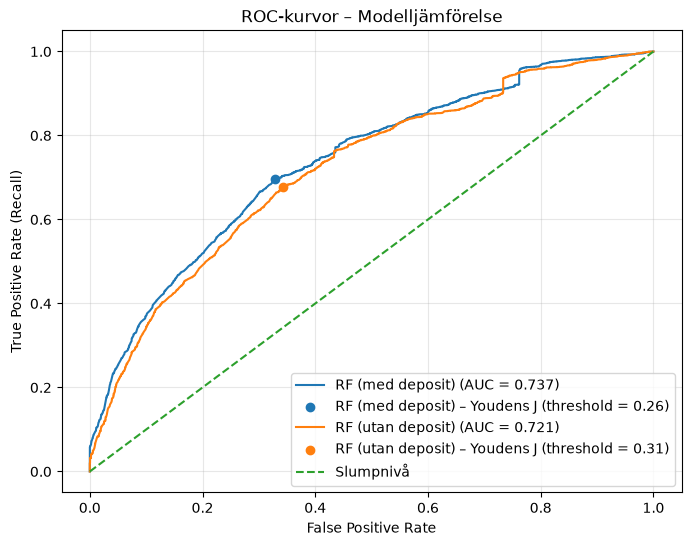

In [13]:
# plot_roc_curve tar en dictionary med modellnamn och tillhörande sannolikheter
roc_results = plot_roc_curve(
    y_val,
    {
        "RF (med deposit)": probas_full,
        "RF (utan deposit)": probas_no_dep
    }
)

# Spara figuren högupplöst till mappen outputs/figures/
save_plot("rf_val_deposit_comparison_roc.png")

#### Feature Importances (vilka variabler väger tyngst?)

In [14]:
# Hämta namnen på alla transformerade kolumner från preprocessorn
feature_names = preprocessor_full.get_feature_names_out()

# Hämta och sortera feature importances fallande
df_importance = get_feature_importances(rf_full, feature_names)

print("Topp 15 viktigaste features i Random Forest:")
display(df_importance.head(15))

Topp 15 viktigaste features i Random Forest:


,feature,importance
0,cat__deposit_type_Non Refund,0.289338
1,cat__deposit_type_No Deposit,0.198917
2,num__previous_cancellations,0.102816
3,num__lead_time,0.089507
4,cat__market_segment_Groups,0.032956
5,cat__customer_type_Transient,0.030668
6,cat__customer_type_Transient-Party,0.026153
7,agent__agent_9,0.021060
8,cat__market_segment_Online TA,0.013733
9,agent__agent_134,0.012027


#### Visa Leaderboard

In [15]:
# Visa sammanställning av alla loggade körningar
leaderboard = get_leaderboard()
display(leaderboard)

,timestamp,model,feature_set,dataset,precision_at_20,recall_at_20,f1_score,antal_flaggade,korrekt_flaggade,notes
0,2026-10-16 16:20,Random Forest,med deposit_type,val,0.6737,0.3820,0.4876,2329,1569,"n_estimators=100, max_depth=15"
1,2026-10-16 16:20,Random Forest,med deposit_type,val,0.6737,0.3820,0.4876,2329,1569,"n_estimators=100, max_depth=15, min_samples_le..."
2,2026-10-17 12:04,Random Forest,med deposit_type,val,0.6690,0.3794,0.4842,2329,1558,"n_estimators=100, max_depth=15, min_samples_le..."
3,2026-10-14 20:17,Random Forest,med deposit_type,val,0.6466,0.3667,0.4680,2329,1506,"n_estimators=100, max_depth=15"
4,2026-10-17 12:04,Random Forest,utan deposit_type,val,0.6462,0.3664,0.4677,2329,1505,"n_estimators=100, max_depth=15, min_samples_le..."
5,2026-10-16 16:22,Random Forest,utan deposit_type,val,0.6406,0.3633,0.4636,2329,1492,"n_estimators=100, max_depth=15, min_samples_le..."
6,2026-10-14 20:17,Random Forest,utan deposit_type,val,0.6385,0.3621,0.4621,2329,1487,"n_estimators=100, max_depth=15"
